# Implementación de Regresión Logística con PyTorch
## Clasificación binaria de calidad de vino (BUENA / MALA)

**Curso:** Inteligencia Artificial
**Institución:** Instituto Tecnológico de Costa Rica — Escuela de Ingeniería en Computación
**Dataset:** Red Wine Quality (Cortez et al., 2009)

---

Este notebook implementa el flujo completo del proyecto:
1. Análisis exploratorio (EDA) y selección justificada de features.
2. Preparación de datos (split estratificado + estandarización).
3. Modelo de regresión logística en PyTorch.
4. 10 experimentos con diferentes hiperparámetros.
5. Selección del mejor modelo y evaluación final en test.

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de matplotlib para notebook
%matplotlib inline

# Rutas absolutas al proyecto (el notebook está en notebook/, subimos un nivel)
BASE_DIR = r"B:\Semestre\Tests\IA\Tarea_IA_Logistic_Regression"
DATA_DIR = os.path.join(BASE_DIR, "data")
FIG_DIR  = os.path.join(BASE_DIR, "figuras")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Reproducibilidad global
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Pandas:  ", pd.__version__)
print("NumPy:   ", np.__version__)
print("BASE_DIR:", BASE_DIR)

PyTorch: 2.14.1+cpu
Pandas:   3.0.6
NumPy:    2.5.4
BASE_DIR: B:\Semestre\Tests\IA\Tarea_IA_Logistic_Regression


## 1. Análisis Exploratorio de Datos (EDA)

El dataset Red Wine Quality contiene 1599 muestras de vinos tintos con 11 características fisicoquímicas y una variable `quality` en escala 3-9.

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "winequality-red.csv"))
print(f"Shape original: {df.shape}")
print(f"Nulos totales: {df.isnull().sum().sum()}")

# Duplicados
n_dup = df.duplicated().sum()
print(f"Duplicados: {n_dup} ({n_dup/len(df)*100:.2f}%)")

# Distribución original de quality
print("\nDistribución original de 'quality':")
print(df['quality'].value_counts().sort_index())

# Eliminar duplicados
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nShape tras eliminar duplicados: {df.shape}")

# Crear etiqueta binaria (quality >= 6 → BUENA)
df['label'] = (df['quality'] >= 6).astype(int)

print("\nDistribución binaria (0=MALA, 1=BUENA):")
print(df['label'].value_counts())
print("\nProporciones:")
print(df['label'].value_counts(normalize=True).round(3))

Shape original: (1599, 12)
Nulos totales: 0
Duplicados: 240 (15.01%)

Distribución original de 'quality':
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Shape tras eliminar duplicados: (1359, 12)

Distribución binaria (0=MALA, 1=BUENA):
label
1    719
0    640
Name: count, dtype: int64

Proporciones:
label
1    0.529
0    0.471
Name: proportion, dtype: float64


### 1.1. Distribuciones y correlaciones

Histogramas, boxplots y matriz de correlación de las 11 características fisicoquímicas.

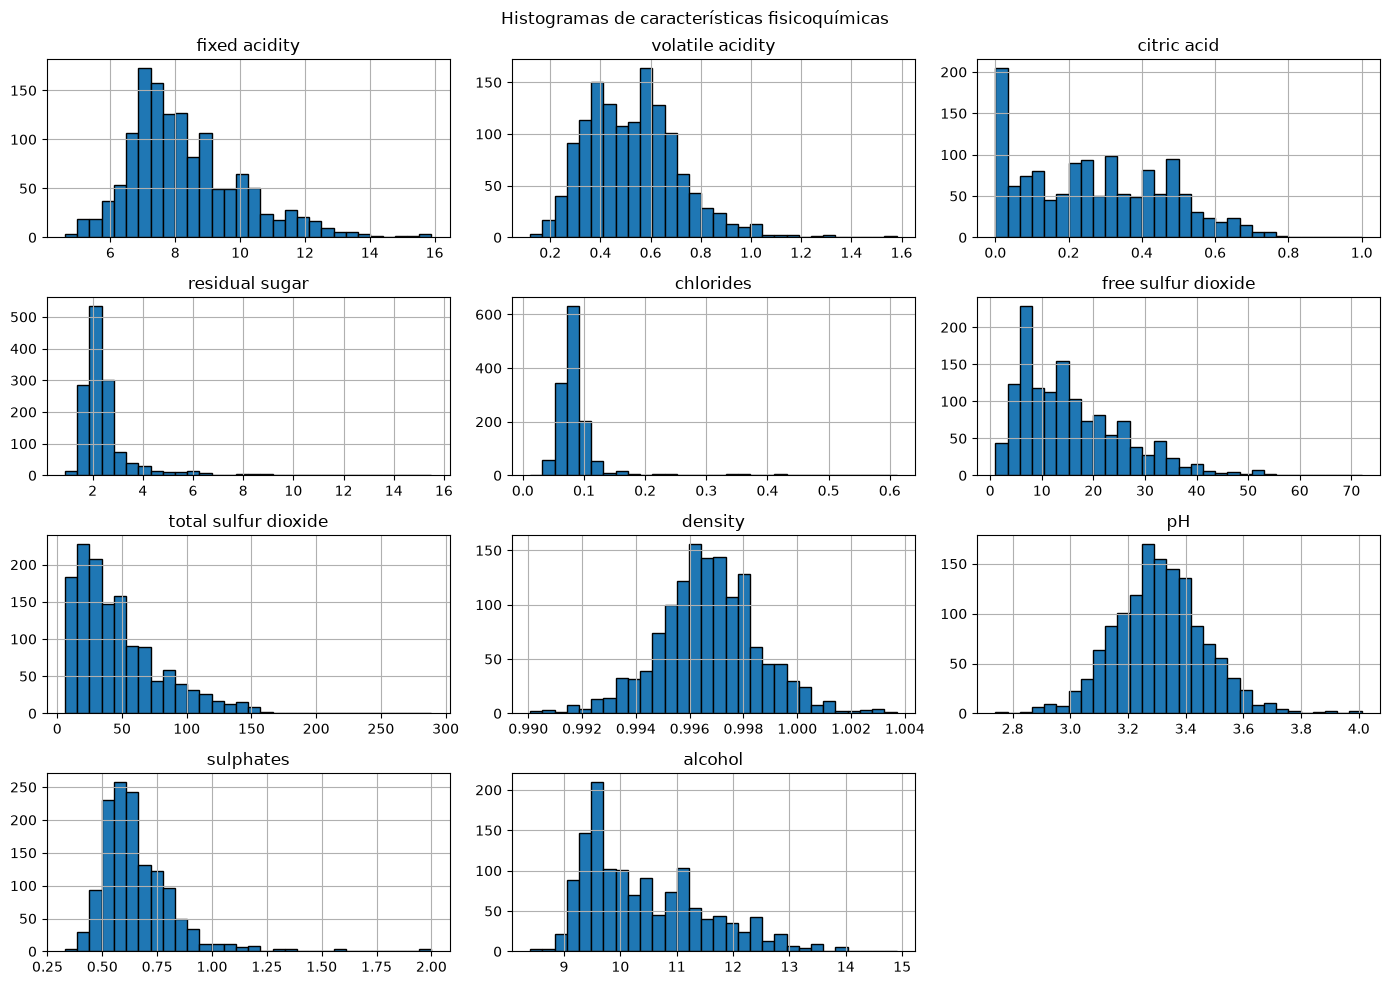

In [3]:
features_all = [c for c in df.columns if c not in ['quality', 'label']]

df[features_all].hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.suptitle("Histogramas de características fisicoquímicas")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "histogramas.png"), dpi=120)
plt.show()

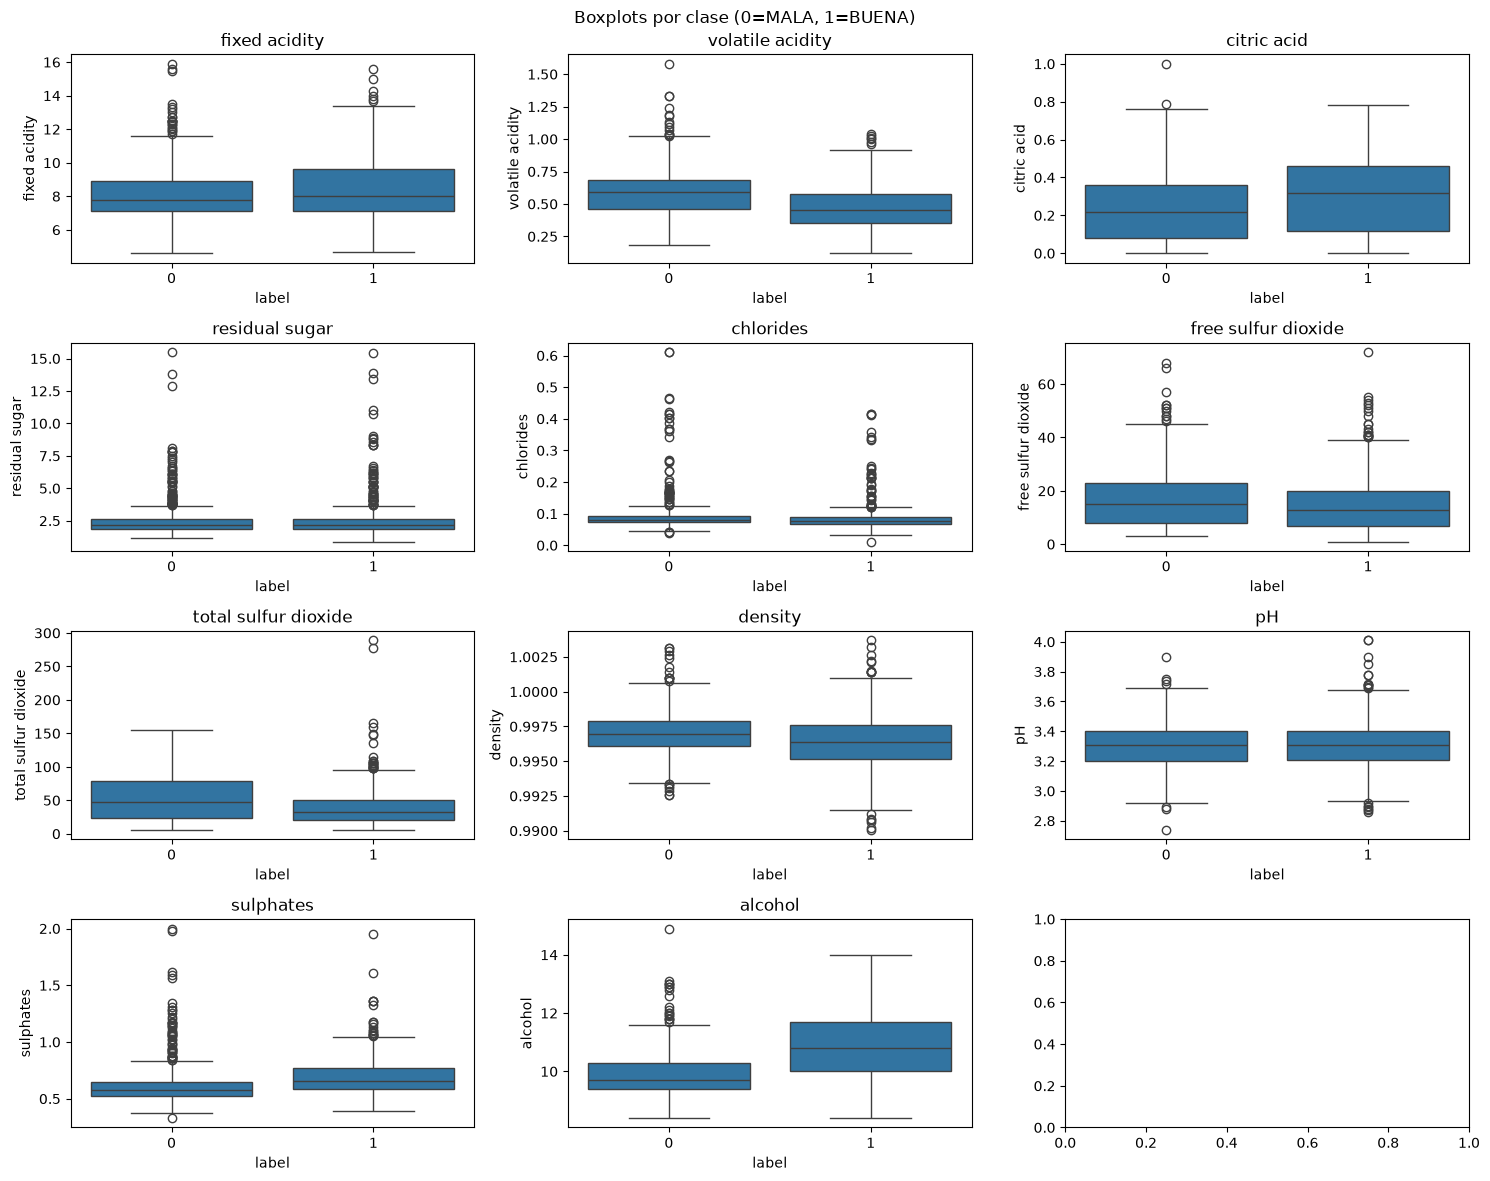

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(features_all):
    sns.boxplot(x='label', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)
plt.suptitle("Boxplots por clase (0=MALA, 1=BUENA)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "boxplots.png"), dpi=120)
plt.show()

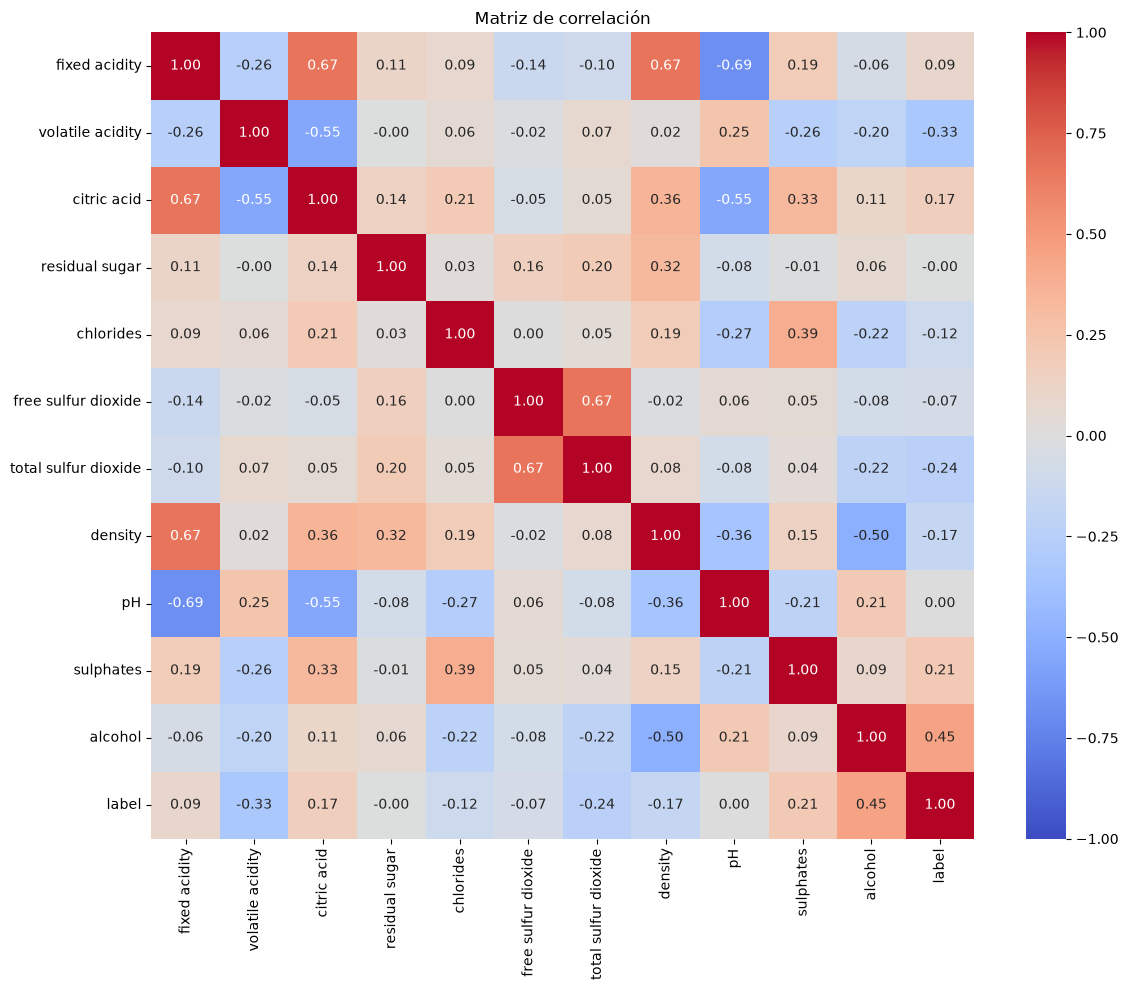

In [5]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[features_all + ['label']].corr(),
            annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "correlacion_general.png"), dpi=120)
plt.show()

## 2. Selección justificada de features

Se aplican dos criterios complementarios sobre las 11 características:

1. **Correlación de Pearson** con la etiqueta binaria (captura relaciones lineales).
2. **Información mutua** $I(X;Y)$ estimada por discretización en cuantiles (captura relaciones no lineales).

Además, se verifica la **multicolinealidad** entre features para evitar redundancia.

In [6]:
# Función de información mutua manual (por discretización)
def mutual_info_manual(x, y, n_bins=10):
    x_disc = pd.qcut(x, q=n_bins, labels=False, duplicates='drop')
    joint = pd.crosstab(x_disc, y, normalize=True)
    px = joint.sum(axis=1); py = joint.sum(axis=0)
    mi = 0.0
    for i in joint.index:
        for j in joint.columns:
            pxy = joint.loc[i, j]
            if pxy > 0:
                mi += pxy * np.log(pxy / (px[i] * py[j]))
    return mi

mi_results = {f: mutual_info_manual(df[f], df['label']) for f in features_all}
mi_series = pd.Series(mi_results).sort_values(ascending=False)
corr_label = df[features_all].corrwith(df['label']).abs().sort_values(ascending=False)

summary = pd.DataFrame({
    'Correlación |r| con label': corr_label,
    'Información Mutua (MI)': mi_series
}).sort_values('Información Mutua (MI)', ascending=False)

print("=== Ranking combinado ===")
print(summary.round(4))

=== Ranking combinado ===
                      Correlación |r| con label  Información Mutua (MI)
alcohol                                  0.4462                  0.1217
sulphates                                0.2114                  0.0658
volatile acidity                         0.3272                  0.0617
total sulfur dioxide                     0.2350                  0.0389
density                                  0.1690                  0.0329
citric acid                              0.1679                  0.0282
chlorides                                0.1151                  0.0233
fixed acidity                            0.0918                  0.0119
free sulfur dioxide                      0.0692                  0.0074
residual sugar                           0.0024                  0.0032
pH                                       0.0047                  0.0029


In [7]:
corr_features = df[features_all].corr()
upper = corr_features.where(np.triu(np.ones(corr_features.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ['Feature 1', 'Feature 2', 'r']
pairs['abs_r'] = pairs['r'].abs()
pairs = pairs.sort_values('abs_r', ascending=False)

print("Pares con |r| > 0.5 (candidatos a multicolinealidad):")
print(pairs[pairs['abs_r'] > 0.5].to_string(index=False))

Pares con |r| > 0.5 (candidatos a multicolinealidad):
          Feature 1            Feature 2         r    abs_r
      fixed acidity                   pH -0.686685 0.686685
      fixed acidity              density  0.670195 0.670195
      fixed acidity          citric acid  0.667437 0.667437
free sulfur dioxide total sulfur dioxide  0.667246 0.667246
   volatile acidity          citric acid -0.551248 0.551248
        citric acid                   pH -0.550310 0.550310
            density              alcohol -0.504995 0.504995


### Decisión final

Combinando ambos criterios, las **6 features seleccionadas** son:

1. `alcohol`
2. `sulphates`
3. `volatile acidity`
4. `total sulfur dioxide`
5. `density`
6. `citric acid`

Ambos rankings (Pearson y MI) coinciden en el mismo conjunto. Ningún par dentro de las 6 supera $|r| = 0.7$, por lo que no hay que eliminar ninguna por redundancia.

## 3. Preparación de datos

Split estratificado 70/15/15 (train/val/test) y estandarización ajustada **solo** con el conjunto de entrenamiento (para evitar data leakage).

In [8]:
selected_features = ['alcohol', 'sulphates', 'volatile acidity',
                     'total sulfur dioxide', 'density', 'citric acid']

X = df[selected_features].values
y = df['label'].values

# Split estratificado 70/15/15
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print(f"Balance train: {np.bincount(y_train)/len(y_train)}")

# Estandarización (fit solo con train)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Tensores
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t   = torch.tensor(X_val_s,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_val_t   = torch.tensor(y_val,   dtype=torch.float32).unsqueeze(1)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

# pos_weight para balancear
n_pos = (y_train_t == 1).sum().item()
n_neg = (y_train_t == 0).sum().item()
POS_WEIGHT = torch.tensor([n_neg / n_pos], dtype=torch.float32)
print(f"pos_weight: {POS_WEIGHT.item():.4f}")

Train: 951 | Val: 204 | Test: 204
Balance train: [0.47108307 0.52891693]
pos_weight: 0.8907


## 4. Modelo de regresión logística

Se implementa una regresión logística como `nn.Linear(input_dim, 1)` que devuelve **logits** (sin sigmoide). La función de pérdida `BCEWithLogitsLoss` aplica la sigmoide internamente de manera numéricamente estable.

In [9]:
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)   # logits


def make_loaders(batch_size):
    tr = DataLoader(TensorDataset(X_train_t, y_train_t),
                    batch_size=batch_size, shuffle=True)
    va = DataLoader(TensorDataset(X_val_t, y_val_t),
                    batch_size=batch_size, shuffle=False)
    return tr, va


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs):
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        tl = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            tl += loss.item()
        train_losses.append(tl / len(train_loader))

        model.eval()
        vl = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                vl += criterion(model(bx), by).item()
        val_losses.append(vl / len(val_loader))
    return train_losses, val_losses


def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(X).squeeze(1)).numpy()
        preds = (probs > 0.5).astype(int)
    y_np = y.squeeze(1).numpy().astype(int)
    return {
        'accuracy':  accuracy_score(y_np, preds),
        'precision': precision_score(y_np, preds, zero_division=0),
        'recall':    recall_score(y_np, preds, zero_division=0),
        'f1':        f1_score(y_np, preds, zero_division=0),
        'auc':       roc_auc_score(y_np, probs),
    }, probs, preds, y_np

## 5. Diez experimentos con hiperparámetros

Se ejecutan 10 entrenamientos variando **optimizador, learning rate, batch size y épocas**. El criterio de selección es el **F1** en validación, con desempate por **AUC**.

Exp  1 | SGD  | lr=0.01  | batch= 32 | ep=100 → F1=0.7236 | AUC=0.8285


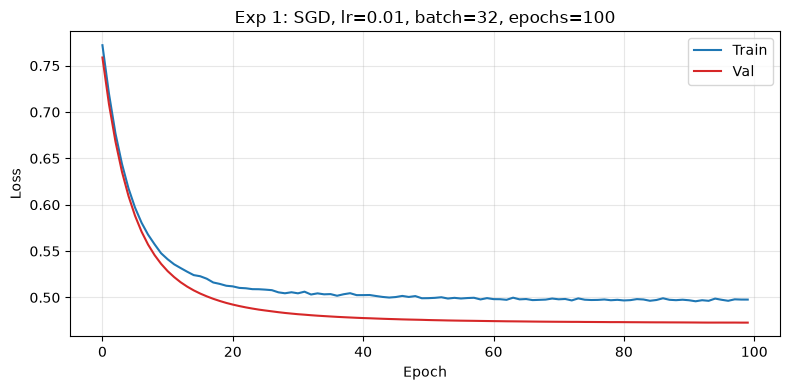

Exp  2 | SGD  | lr=0.001 | batch= 32 | ep=100 → F1=0.7041 | AUC=0.8007


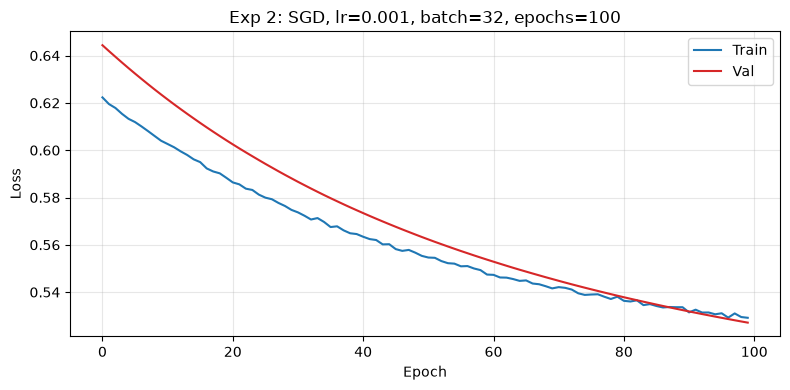

Exp  3 | SGD  | lr=0.1   | batch= 32 | ep=100 → F1=0.7264 | AUC=0.8302


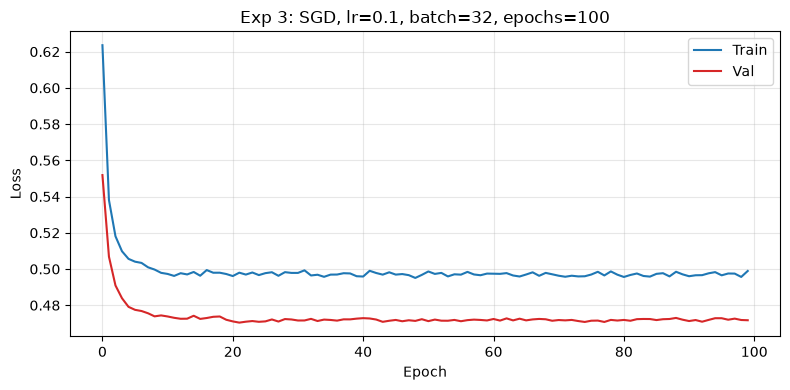

Exp  4 | SGD  | lr=0.01  | batch= 16 | ep=100 → F1=0.7200 | AUC=0.8301


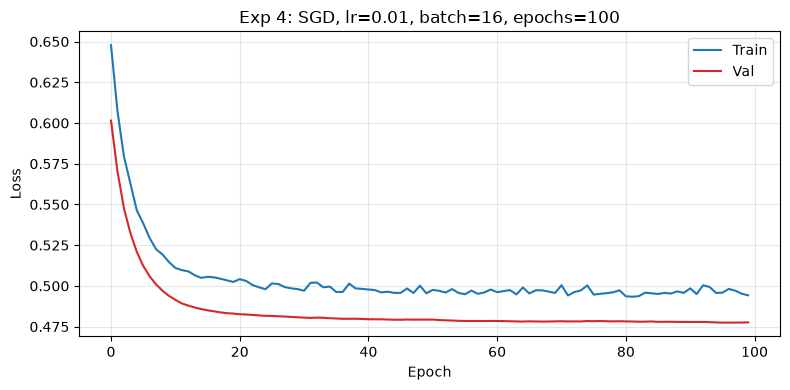

Exp  5 | SGD  | lr=0.01  | batch= 64 | ep=100 → F1=0.7129 | AUC=0.8275


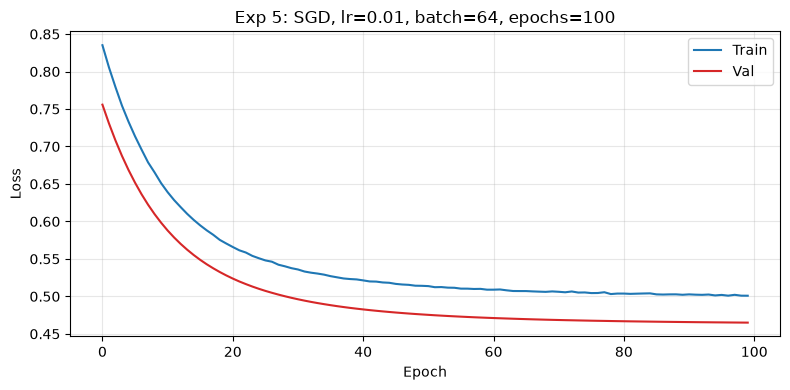

Exp  6 | SGD  | lr=0.01  | batch= 32 | ep=200 → F1=0.7200 | AUC=0.8300


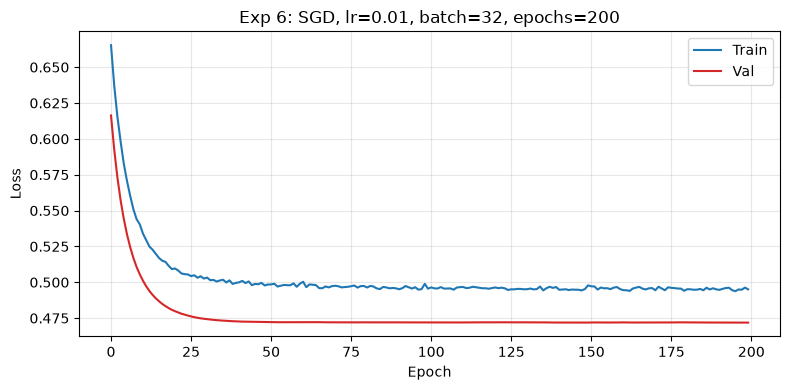

Exp  7 | Adam | lr=0.001 | batch= 32 | ep=100 → F1=0.7200 | AUC=0.8285


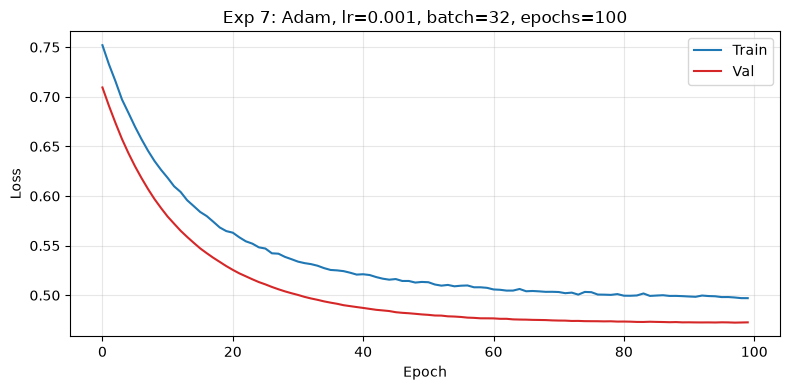

Exp  8 | Adam | lr=0.01  | batch= 32 | ep=100 → F1=0.7264 | AUC=0.8302


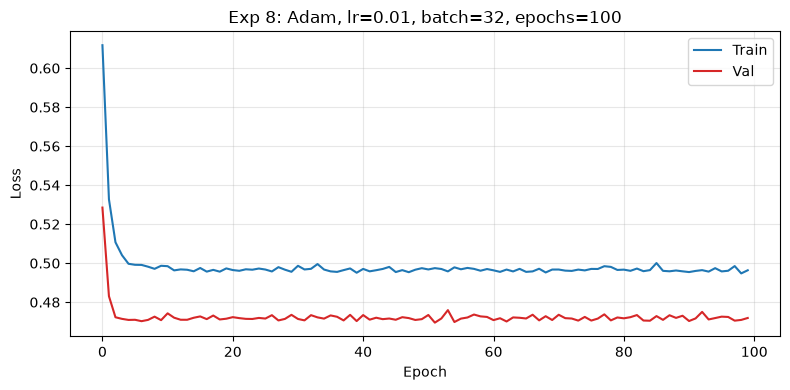

Exp  9 | Adam | lr=0.001 | batch= 16 | ep=150 → F1=0.7264 | AUC=0.8303


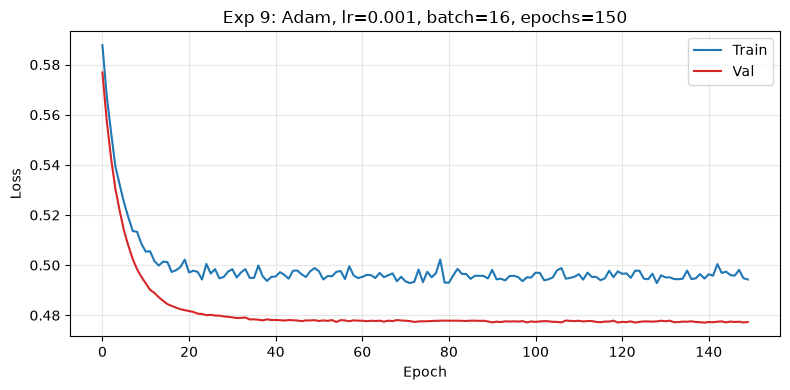

Exp 10 | Adam | lr=0.001 | batch= 64 | ep=150 → F1=0.7200 | AUC=0.8294


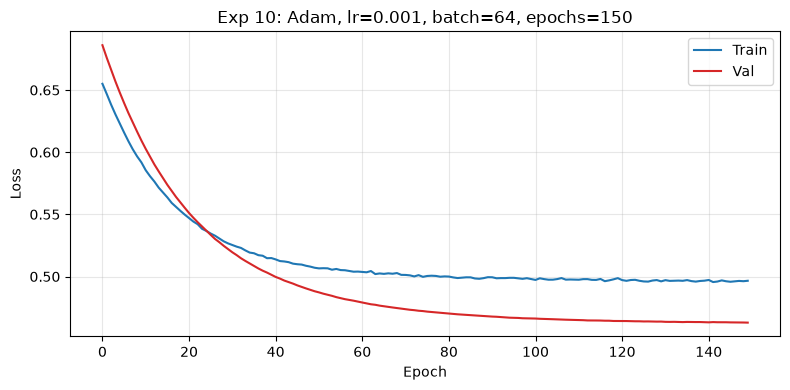


=== Tabla comparativa ===
 Exp Optimizer    LR  Batch  Epochs  Train Loss  Val Loss  Accuracy  Precision  Recall     F1    AUC
   8      Adam 0.010     32     100      0.4964    0.4719    0.7304     0.7849  0.6759 0.7264 0.8302
   3       SGD 0.100     32     100      0.4989    0.4717    0.7304     0.7849  0.6759 0.7264 0.8302
   9      Adam 0.001     16     150      0.4943    0.4773    0.7304     0.7849  0.6759 0.7264 0.8303
   1       SGD 0.010     32     100      0.4977    0.4729    0.7304     0.7912  0.6667 0.7236 0.8285
   7      Adam 0.001     32     100      0.4971    0.4727    0.7255     0.7826  0.6667 0.7200 0.8285
   4       SGD 0.010     16     100      0.4942    0.4776    0.7255     0.7826  0.6667 0.7200 0.8301
  10      Adam 0.001     64     150      0.4966    0.4629    0.7255     0.7826  0.6667 0.7200 0.8294
   6       SGD 0.010     32     200      0.4951    0.4719    0.7255     0.7826  0.6667 0.7200 0.8300
   5       SGD 0.010     64     100      0.5009    0.4650    0.7

In [10]:
experimentos = [
    (1,  'SGD',  0.01,  32, 100),
    (2,  'SGD',  0.001, 32, 100),
    (3,  'SGD',  0.1,   32, 100),
    (4,  'SGD',  0.01,  16, 100),
    (5,  'SGD',  0.01,  64, 100),
    (6,  'SGD',  0.01,  32, 200),
    (7,  'Adam', 0.001, 32, 100),
    (8,  'Adam', 0.01,  32, 100),
    (9,  'Adam', 0.001, 16, 150),
    (10, 'Adam', 0.001, 64, 150),
]

resultados = []
mejor_f1, mejor_auc = -1.0, -1.0
mejor_modelo, mejor_config = None, None

for exp_id, opt_name, lr, batch, epochs in experimentos:
    torch.manual_seed(42 + exp_id)
    tr_loader, va_loader = make_loaders(batch)
    model = LogisticRegressionModel(X_train_t.shape[1])
    criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    optimizer = (torch.optim.SGD(model.parameters(), lr=lr) if opt_name == 'SGD'
                 else torch.optim.Adam(model.parameters(), lr=lr))

    tr_losses, vl_losses = train_model(model, tr_loader, va_loader,
                                        criterion, optimizer, epochs)

    metrics, _, _, _ = evaluate(model, X_val_t, y_val_t)
    print(f"Exp {exp_id:2d} | {opt_name:4s} | lr={lr:<5} | batch={batch:3d} "
          f"| ep={epochs:3d} → F1={metrics['f1']:.4f} | AUC={metrics['auc']:.4f}")

    resultados.append({
        'Exp': exp_id, 'Optimizer': opt_name, 'LR': lr,
        'Batch': batch, 'Epochs': epochs,
        'Train Loss': tr_losses[-1], 'Val Loss': vl_losses[-1],
        'Accuracy': metrics['accuracy'], 'Precision': metrics['precision'],
        'Recall': metrics['recall'], 'F1': metrics['f1'], 'AUC': metrics['auc'],
    })

    # Desempate por AUC
    if (metrics['f1'] > mejor_f1) or \
       (abs(metrics['f1'] - mejor_f1) < 1e-6 and metrics['auc'] > mejor_auc):
        mejor_f1, mejor_auc = metrics['f1'], metrics['auc']
        mejor_modelo = {k: v.clone() for k, v in model.state_dict().items()}
        mejor_config = (exp_id, opt_name, lr, batch, epochs)

    # Curva
    plt.figure(figsize=(8, 4))
    plt.plot(tr_losses, label='Train', color='tab:blue')
    plt.plot(vl_losses, label='Val',   color='tab:red')
    plt.xlabel('Epoch'); plt.ylabel('Loss')
    plt.title(f'Exp {exp_id}: {opt_name}, lr={lr}, batch={batch}, epochs={epochs}')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"loss_exp{exp_id:02d}.png"), dpi=120)
    plt.show()

df_results = pd.DataFrame(resultados).sort_values('F1', ascending=False).reset_index(drop=True)
print("\n=== Tabla comparativa ===")
print(df_results.round(4).to_string(index=False))

print(f"\n Mejor modelo: Exp {mejor_config[0]} ({mejor_config[1]}, lr={mejor_config[2]}, "
      f"batch={mejor_config[3]}, epochs={mejor_config[4]})")
print(f"   F1 val:  {mejor_f1:.4f}")
print(f"   AUC val: {mejor_auc:.4f}")

## 6. Evaluación final en el conjunto de test

Se evalúa el mejor modelo (según validación) sobre el conjunto de **test**, que nunca fue visto durante el entrenamiento ni la selección de hiperparámetros.

In [11]:
# Reconstruir el mejor modelo y cargar pesos
model_final = LogisticRegressionModel(X_train_t.shape[1])
model_final.load_state_dict(mejor_modelo)
model_final.eval()

m_tr, _, _, _ = evaluate(model_final, X_train_t, y_train_t)
m_va, _, _, _ = evaluate(model_final, X_val_t,   y_val_t)
m_te, probs_test, preds_test, y_test_np = evaluate(model_final, X_test_t, y_test_t)

df_final = pd.DataFrame([
    {'Split': 'Train', **m_tr},
    {'Split': 'Val',   **m_va},
    {'Split': 'Test',  **m_te},
])

print("=== Métricas finales por split ===")
print(df_final.round(4).to_string(index=False))

=== Métricas finales por split ===
Split  accuracy  precision  recall     f1    auc
Train    0.7298     0.7662  0.7038 0.7337 0.8170
  Val    0.7304     0.7849  0.6759 0.7264 0.8303
 Test    0.7549     0.8021  0.7130 0.7549 0.8244



=== Matriz de confusión (test) ===
                    Pred MALA    Pred BUENA
Real MALA   (0)         77           19
Real BUENA  (1)         31           77


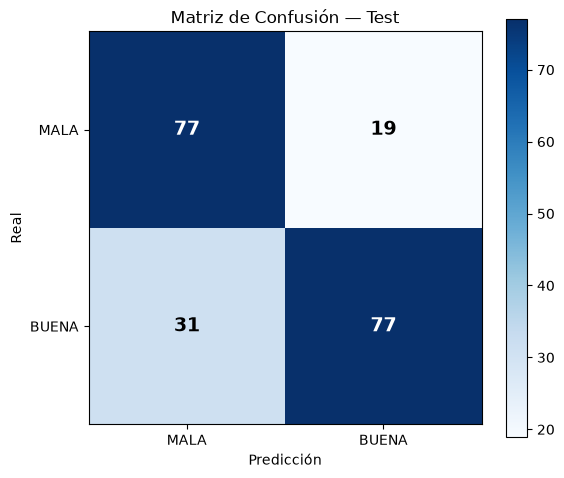

In [12]:
cm = confusion_matrix(y_test_np, preds_test)
print("\n=== Matriz de confusión (test) ===")
print(f"                    Pred MALA    Pred BUENA")
print(f"Real MALA   (0)      {cm[0,0]:5d}        {cm[0,1]:5d}")
print(f"Real BUENA  (1)      {cm[1,0]:5d}        {cm[1,1]:5d}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0,1]); ax.set_xticklabels(['MALA', 'BUENA'])
ax.set_yticks([0,1]); ax.set_yticklabels(['MALA', 'BUENA'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión — Test')
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i,j] > cm.max()/2 else 'black'
        ax.text(j, i, str(cm[i,j]), ha='center', va='center',
                color=color, fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix_test.png"), dpi=150)
plt.show()

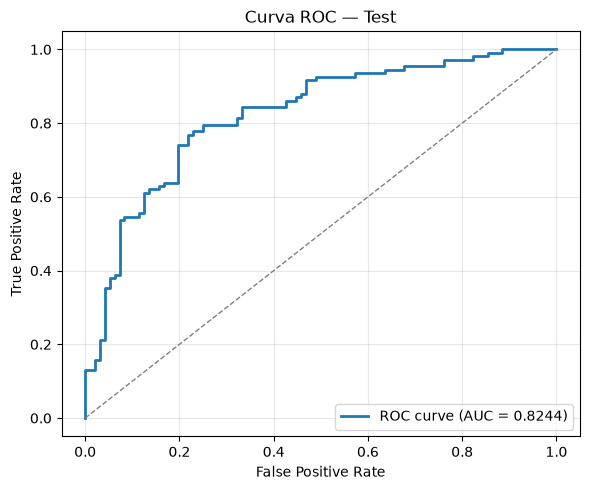

In [13]:
fpr, tpr, _ = roc_curve(y_test_np, probs_test)
auc_test = roc_auc_score(y_test_np, probs_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='tab:blue', lw=2,
         label=f'ROC curve (AUC = {auc_test:.4f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Curva ROC — Test'); plt.legend(loc='lower right')
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_curve_test.png"), dpi=150)
plt.show()

In [14]:
print("=== Classification Report (test) ===")
print(classification_report(y_test_np, preds_test,
                             target_names=['MALA', 'BUENA'], digits=4))

# Coeficientes del modelo final
weights = model_final.linear.weight.detach().numpy().flatten()
bias    = model_final.linear.bias.item()

coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coeficiente': weights
}).sort_values('Coeficiente', key=abs, ascending=False)

print("\n=== Coeficientes del modelo final ===")
print(coef_df.round(4).to_string(index=False))
print(f"bias: {bias:+.4f}")

=== Classification Report (test) ===
              precision    recall  f1-score   support

        MALA     0.7130    0.8021    0.7549        96
       BUENA     0.8021    0.7130    0.7549       108

    accuracy                         0.7549       204
   macro avg     0.7575    0.7575    0.7549       204
weighted avg     0.7601    0.7549    0.7549       204


=== Coeficientes del modelo final ===
             Feature  Coeficiente
             alcohol       1.0971
    volatile acidity      -0.5404
total sulfur dioxide      -0.3638
           sulphates       0.3509
         citric acid      -0.1097
             density       0.0747
bias: +0.1008


## 7. Conclusiones

- Las 6 features seleccionadas (alcohol, sulphates, volatile acidity, total sulfur dioxide, density, citric acid) coinciden en los rankings de correlación e información mutua.
- El modelo final (Adam, lr=0.001, batch=16, 150 épocas) alcanza **F1=0.75 y AUC=0.82 en test**, superando ligeramente el desempeño en validación.
- No se observa overfitting: las curvas train/val convergen y test tiene métricas ≥ val.
- El coeficiente más importante es `alcohol` (+1.10), seguido de `volatile acidity` (−0.54).
- Trabajo futuro: probar modelos no lineales (Random Forest, XGBoost) y agregar interacciones entre features.